## Build a chatbot using langgraph

### components of langgraph
    - Nodes: Individual steps in the graph
    - Edges: Connections between nodes that define the flow of data
    - Graph: The overall structure that connects nodes and edges to represent a process or workflow
    - State: The current status or context of the graph, which can be used to store and manage data as it flows through the nodes

In [1]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from dotenv import load_dotenv
load_dotenv()

True

why add_messages:

    The `add_messages` function is typically used in chatbot development to manage the conversation history between the user and the chatbot. Here are some reasons why you might want to use `add_messages`:1. **Maintain Context**: By storing previous messages, the chatbot can maintain context throughout the conversation. This allows the chatbot to provide more relevant and coherent responses based on the history of the interaction.


why Annotated:

    The `Annotated` type is used to provide additional metadata or information about a variable or parameter in programming. It allows developers to attach extra context, such as descriptions, constraints, or other relevant details, to a variable. This can be useful for documentation, validation, and improving code readability. In the context of chatbot development, using `Annotated` can help clarify the purpose and expected behavior of certain variables or parameters, making the code easier to understand and maintain.

In [2]:
from langchain_groq import ChatGroq
model = ChatGroq(model="openai/gpt-oss-20b", temperature=0.3)

In [3]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

In [4]:
graph = StateGraph(State)
graph

In [5]:
def chatbot(state: State):
    return {"messages" : [model.invoke(state["messages"])]}

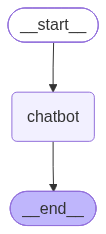

In [6]:
graph.add_node("chatbot", chatbot)

graph.add_edge(START, "chatbot")
graph.add_edge("chatbot", END)

final_graph = graph.compile()
final_graph

In [7]:
response = final_graph.invoke({"messages" : "write a some Indian ladies name in this trending. Give me just list of names"})

In [8]:
response["messages"][-1].content

'Aaradhya  \nAnanya  \nIsha  \nMira  \nRiya  \nSaanvi  \nSofia  \nTara  \nVeda  \nYashvi  \nZara  \nKavya  \nNisha  \nRhea  \nSahana  \nMeera  \nDiya  \nPrisha  \nKriti  \nAnika'

## Chatbot with tools:

    A chatbot with tools refers to a conversational AI system that is equipped with various functionalities or "tools" to enhance its capabilities. These tools can include features like natural language understanding, sentiment analysis, knowledge retrieval, and integration with external APIs or databases. By incorporating these tools, the chatbot can provide more accurate responses, perform specific tasks, and offer a richer user experience. For example, a chatbot with tools might be able to answer complex questions, schedule appointments, or provide personalized recommendations based on user input.

In [9]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2, topic="general")
# tool.invoke("what is langgraph?")

## Custom functions:

    Custom functions in the context of a chatbot refer to user-defined functions that can be created to extend the chatbot's capabilities. These functions can be tailored to perform specific tasks or handle unique scenarios that are not covered by the default functionality of the chatbot framework. By implementing custom functions, developers can create more personalized and specialized interactions, allowing the chatbot to better meet the needs of its users. Examples of custom functions might include processing user input in a specific way, integrating with third-party services, or executing complex business logic based on user requests.

In [10]:
def multiplication(a: int, b: int):
    """ 

    Multiply two numbers.

      Parameters:
        a (int or float): The first number to multiply.
        b (int or float): The second number to multiply.

      Returns:
        int or float: The product of the two numbers.
        
      Example:
        >>> multiply(2, 3)
        6
        >>> multiply(4.5, 2)
        9.0
        return a * b
    
    """

    return a * b

In [11]:
tools = [tool, multiplication]

In [12]:
llm_with_tools = model.bind_tools(tools=tools)
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000019DB2631550>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000019DB2631FD0>, model_name='openai/gpt-oss-20b', temperature=0.3, model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensiv

In [13]:
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

In [14]:
def tool_with_llm(state: State):
    return {"messages" : [llm_with_tools.invoke(state['messages'])]}

In [15]:
graph = StateGraph(State)
graph.add_node("too_calling_llm", tool_with_llm)
graph.add_node("tools", ToolNode(tools))

In [16]:
graph.add_edge(START, "too_calling_llm")
graph.add_conditional_edges("too_calling_llm", tools_condition)
graph.add_edge("tools", END)

final_graph = graph.compile()

In [17]:
response = final_graph.invoke({"messages" : "what is the letest news of war"})
response["messages"][-1].content

'{"query": "latest war news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://indianexpress.com/article/world/us-iran-war-live-updates-trump-eyes-tehran-strikes-israel-netanyahu-hormuz-shipping-india-oil-prices-global-markets-10974195", "title": "US-Iran War Live Updates: Tehran attack US drones, Yemen Air Strikes, Saudi Intercepts Houthi Drone, Strait of Hormuz, Israel, Trump, Netanyahu Latest News | World News - The Indian Express", "content": "Tension across the Gulf is rising again, even as Iran and the United States say they are still talking. US President Donald Trump told Fox News on Sunday that he is “inclined” to restart the war on Iran in the new year if no deal is reached, while the US naval blockade of Iranian shipping stays in place. Iran says it is ready for any outcome, and its deputy foreign minister said talks with Washington are continuing. On the ground and at sea, attacks have not stopped. Iran has struck targets in Bahrain, Y

In [18]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

what is the letest news of war
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_74f5bce8-a603-4a6b-8da2-19110e17a8e7)
 Call ID: fc_74f5bce8-a603-4a6b-8da2-19110e17a8e7
  Args:
    query: latest war news
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest war news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://indianexpress.com/article/world/us-iran-war-live-updates-trump-eyes-tehran-strikes-israel-netanyahu-hormuz-shipping-india-oil-prices-global-markets-10974195", "title": "US-Iran War Live Updates: Tehran attack US drones, Yemen Air Strikes, Saudi Intercepts Houthi Drone, Strait of Hormuz, Israel, Trump, Netanyahu Latest News | World News - The Indian Express", "content